# Project Deliverable 2: Regression Modeling and Performance Evaluation
**Name:** Rohail Shaikh,Abhilash Reddy Marthala, Phaneendra vanapamula 

**Course:** Advanced Big Data and Data Mining (MSCS-634-M50)  
**Project:** Advanced Data Mining for Data-Driven Insights and Predictive Modeling

This notebook continues Deliverable 1 using the **UCI Bike Sharing dataset**. The goal is to
predict total hourly rentals from calendar and weather information. It compares Multiple
Linear Regression and Ridge Regression, measures the effect of new features, and evaluates
performance on later observations.

## 1. Load the cleaned dataset

The dataset contains **17,379 recorded hours and 17 columns** from 2011–2012 in Washington,
D.C. (Fanaee-T, 2013). The target is `total_rentals`, originally named `cnt`.
The included CSV is the cleaned dataset from Deliverable 1. No records are removed here,
and absent hours are not filled with invented rental counts.

`casual_rentals` and `registered_rentals` are excluded from every model because their sum
equals the target. The timestamp orders the records; it is not passed directly to regression.
Run the notebook from this folder so it can find the CSV.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error

pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

df = pd.read_csv('bike_sharing_cleaned.csv', parse_dates=['date', 'timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

# Confirm that the cleaned data still has valid hourly records and rental totals.
assert df.shape == (17379, 17)
assert not df.isna().any().any()
assert not df['timestamp'].duplicated().any()
assert (df['total_rentals'] == df['casual_rentals'] + df['registered_rentals']).all()
print(f'Records: {len(df):,}; columns: {df.shape[1]}')
print(f"Period: {df['timestamp'].min()} to {df['timestamp'].max()}")
display(df[['timestamp', 'hour', 'working_day', 'temperature_norm', 'total_rentals']].head())

Records: 17,379; columns: 17
Period: 2011-01-01 00:00:00 to 2012-12-31 23:00:00


,timestamp,hour,working_day,temperature_norm,total_rentals
0,2011-01-01 00:00:00,0,0,0.2400,16
1,2011-01-01 01:00:00,1,0,0.2200,40
2,2011-01-01 02:00:00,2,0,0.2200,32
3,2011-01-01 03:00:00,3,0,0.2400,13
4,2011-01-01 04:00:00,4,0,0.2400,1


## 2. Feature engineering

Deliverable 1 showed different hourly patterns on working and non-working days, along with
growth across the two years. These findings guide three groups of new features.

| New features | How they are created | Purpose |
|---|---|---|
| `hour_sin_1` to `hour_sin_3`, `hour_cos_1` to `hour_cos_3` | Sine and cosine of hour at 24-, 12-, and 8-hour periods | Represent a repeating daily pattern with more than one peak; hour 23 stays close to hour 0. |
| `work_hour_sin_1` to `work_hour_sin_3`, `work_hour_cos_1` to `work_hour_cos_3` | Each cyclic feature multiplied by `working_day` | Allow the daily curve to change on working days. |
| `days_since_start` | Days since January 1, 2011 | Represent gradual growth rather than only a change between years. |

These **13 new features** use only calendar information and fixed formulas. They do not use
rental totals or fitted statistics. The raw hour stays in the baseline and engineered models,
so the comparison measures the effect of adding these features. Using cyclic time features
with linear models follows the approach described in scikit-learn's time feature example.

In [2]:
engineered_features = []
for harmonic in (1, 2, 3):
    angle = 2 * np.pi * harmonic * df['hour'] / 24
    for label, values in [('sin', np.sin(angle)), ('cos', np.cos(angle))]:
        name = f'hour_{label}_{harmonic}'
        work_name = f'work_{name}'
        df[name] = values
        df[work_name] = values * df['working_day']
        engineered_features.extend([name, work_name])

# Use a fixed calendar origin, so future dates can be transformed the same way.
df['days_since_start'] = (df['timestamp'] - pd.Timestamp('2011-01-01')).dt.total_seconds() / 86400
engineered_features.append('days_since_start')

base_numeric = ['hour', 'year', 'working_day', 'holiday', 'temperature_norm',
                'feels_like_norm', 'humidity_norm', 'windspeed_norm']
categorical = ['month', 'season', 'weather']
all_predictors = base_numeric + categorical + engineered_features
X = df[all_predictors].copy()
y = df['total_rentals'].copy()
assert not {'total_rentals', 'casual_rentals', 'registered_rentals'} & set(X.columns)
print(f'Baseline: {len(base_numeric) + len(categorical)} input columns')
print(f'Engineered: {len(all_predictors)} input columns, including {len(engineered_features)} new features')
display(df[['hour', 'working_day', 'hour_sin_1', 'hour_cos_1',
            'work_hour_sin_1', 'days_since_start']].head())

Baseline: 11 input columns
Engineered: 24 input columns, including 13 new features


,hour,working_day,hour_sin_1,hour_cos_1,work_hour_sin_1,days_since_start
0,0,0,0.0000,1.0000,0.0000,0.0000
1,1,0,0.2588,0.9659,0.0000,0.0417
2,2,0,0.5000,0.8660,0.0000,0.0833
3,3,0,0.7071,0.7071,0.0000,0.1250
4,4,0,0.8660,0.5000,0.0000,0.1667


## 3. Chronological training, validation, and testing

Records before **August 1, 2012** are used for training and model selection. The remaining
five months are held out for final evaluation. The data is not shuffled.

Five expanding validation folds each cover **two calendar months**. Every fold trains on
earlier dates and validates on the next period. Calendar windows keep the duration consistent
despite unrecorded hours. Scaling and one-hot encoding are fitted inside each training fold.

In [3]:
cutoff = pd.Timestamp('2012-08-01')
train_mask = df['timestamp'] < cutoff
X_train, X_test = X.loc[train_mask].copy(), X.loc[~train_mask].copy()
y_train, y_test = y.loc[train_mask].copy(), y.loc[~train_mask].copy()
train_times = df.loc[train_mask, 'timestamp'].reset_index(drop=True)
test_times = df.loc[~train_mask, 'timestamp'].reset_index(drop=True)

# GridSearchCV accepts positional train/validation indices for each calendar window.
cv_splits, fold_rows = [], []
for fold, start in enumerate(pd.to_datetime([
    '2011-10-01', '2011-12-01', '2012-02-01', '2012-04-01', '2012-06-01'
]), start=1):
    end = start + pd.DateOffset(months=2)
    train_idx = np.flatnonzero(train_times < start)
    valid_idx = np.flatnonzero((train_times >= start) & (train_times < end))
    assert train_times.iloc[train_idx].max() < train_times.iloc[valid_idx].min()
    cv_splits.append((train_idx, valid_idx))
    fold_rows.append({'Fold': fold, 'Train through': str(train_times.iloc[train_idx].max().date()),
                      'Validate from': str(start.date()),
                      'Validate through': str((end - pd.Timedelta(days=1)).date()),
                      'Train rows': len(train_idx), 'Validation rows': len(valid_idx)})

assert train_times.max() < test_times.min()
print(f'Training: {len(X_train):,} rows ({len(X_train) / len(X):.1%})')
print(f'Test: {len(X_test):,} rows ({len(X_test) / len(X):.1%})')
display(pd.DataFrame(fold_rows))

Training: 13,747 rows (79.1%)
Test: 3,632 rows (20.9%)


,Fold,Train through,Validate from,Validate through,Train rows,Validation rows
0,1,2011-09-30,2011-10-01,2011-11-30,6442,1462
1,2,2011-11-30,2011-12-01,2012-01-31,7904,1482
2,3,2012-01-31,2012-02-01,2012-03-31,9386,1435
3,4,2012-03-31,2012-04-01,2012-05-31,10821,1462
4,5,2012-05-31,2012-06-01,2012-07-31,12283,1464


## 4. Regression models and cross-validation

Three versions provide a fair comparison:

1. **Linear baseline:** Multiple Linear Regression using the 11 original input columns.
2. **Linear engineered:** The same algorithm with the 13 new features added.
3. **Ridge engineered:** The engineered inputs with L2 regularization, which shrinks
   coefficients and can help when predictors are correlated (Wu, 2024, Chapter 7).

Numeric inputs are standardized. Month, season, and weather codes are one-hot encoded,
since their numeric labels do not imply equal changes in demand. Their possible categories
come from the dataset definitions, not from future records. Weekday is omitted because
working-day and holiday status already summarize the main day-type distinction.

Ridge compares `alpha = 0.1, 1, 10, 100` using only the five training folds. A higher alpha
means more shrinkage. The model and alpha with the lowest mean validation RMSE are selected
before evaluating the test period. The CV scores used for selection are not an independent
evaluation of that selection.

- **R²:** Relative improvement over predicting the evaluation period's mean. Higher is better;
  it can be negative. It is not a percentage of predictions that are correct.
- **MSE:** Mean squared error, in squared rental counts. Lower is better.
- **RMSE:** Square root of MSE, in rentals per recorded hour. Lower is better; larger misses
  receive more weight.

In [4]:
def make_pipeline(numeric_columns, regressor):
    # All fitted transformations stay inside the model pipeline.
    preprocessing = ColumnTransformer([
        ('numeric', StandardScaler(), numeric_columns),
        ('category', OneHotEncoder(
            categories=[list(range(1, 13)), [1, 2, 3, 4], [1, 2, 3, 4]],
            drop='first', handle_unknown='ignore', sparse_output=False
        ), categorical)
    ])
    return Pipeline([('preprocess', preprocessing), ('regression', regressor)])

model_specs = {
    'Linear baseline': (base_numeric, LinearRegression(), {}),
    'Linear engineered': (base_numeric + engineered_features, LinearRegression(), {}),
    'Ridge engineered': (base_numeric + engineered_features, Ridge(),
                         {'regression__alpha': [0.1, 1.0, 10.0, 100.0]})
}
scoring = {'r2': 'r2', 'mse': 'neg_mean_squared_error', 'rmse': 'neg_root_mean_squared_error'}
searches, cv_rows, cv_fold_rows = {}, [], []

for name, (numeric_columns, regressor, parameters) in model_specs.items():
    search = GridSearchCV(make_pipeline(numeric_columns, regressor), parameters,
                          scoring=scoring, refit='rmse', cv=cv_splits,
                          n_jobs=1, error_score='raise')
    search.fit(X_train, y_train)
    searches[name] = search
    index = search.best_index_
    result = search.cv_results_
    cv_rows.append({'Model': name, 'CV R2': result['mean_test_r2'][index],
                    'CV MSE': -result['mean_test_mse'][index],
                    'CV RMSE': -result['mean_test_rmse'][index],
                    'CV RMSE SD': result['std_test_rmse'][index]})
    for fold in range(5):
        cv_fold_rows.append({'Model': name, 'Fold': fold + 1,
                            'R2': result[f'split{fold}_test_r2'][index],
                            'RMSE': -result[f'split{fold}_test_rmse'][index]})

cv_results = pd.DataFrame(cv_rows).set_index('Model')
best_name = cv_results['CV RMSE'].idxmin()
ridge_alpha = searches['Ridge engineered'].best_params_['regression__alpha']
display(cv_results.round(4))
display(pd.DataFrame(cv_fold_rows).pivot(index='Fold', columns='Model', values='RMSE').round(2))
print(f'Selected Ridge alpha: {ridge_alpha:g}')
print(f'Model selected using validation RMSE: {best_name}')

,CV R2,CV MSE,CV RMSE,CV RMSE SD
Model,,,,
Linear baseline,0.2612,"22,126.7518",145.2386,32.1325
Linear engineered,0.5854,"11,343.1047",104.9989,17.8421
Ridge engineered,0.6567,"10,472.5296",99.5882,23.5526


Model,Linear baseline,Linear engineered,Ridge engineered
Fold,,,
1,109.9800,77.7000,75.7700
2,107.0500,97.1200,69.6700
3,149.3700,101.2300,102.4200
4,175.4000,122.0500,123.1000
5,184.4000,126.9000,126.9800


Selected Ridge alpha: 100
Model selected using validation RMSE: Ridge engineered


## 5. Final model evaluation and comparison

Each selected pipeline has been refitted on all training records. The following table evaluates
the three fixed candidates on the same later test period. Test scores are not used to change
features, tune alpha, or select the recommended model. The baseline and engineered linear
models isolate the effect of feature engineering.

In [5]:
predictions, test_rows = {}, []
for name, search in searches.items():
    model = search.best_estimator_
    predicted = model.predict(X_test)
    predictions[name] = predicted
    mse = mean_squared_error(y_test, predicted)
    test_rows.append({'Model': name, 'Train R2': r2_score(y_train, model.predict(X_train)),
                      'Test R2': r2_score(y_test, predicted), 'Test MSE': mse,
                      'Test RMSE': np.sqrt(mse)})

comparison = pd.DataFrame(test_rows).set_index('Model').join(cv_results)
comparison.index.name = 'Model'
comparison.round(4).to_csv('model_comparison.csv')
display(comparison.round(4))

base = comparison.loc['Linear baseline']
engineered = comparison.loc['Linear engineered']
cv_improvement = 100 * (base['CV RMSE'] - engineered['CV RMSE']) / base['CV RMSE']
test_improvement = 100 * (base['Test RMSE'] - engineered['Test RMSE']) / base['Test RMSE']
test_best_name = comparison['Test RMSE'].idxmin()
best_predictions = predictions[best_name]

print(f'Feature engineering reduced CV RMSE by {cv_improvement:.1f}%.')
print(f'Feature engineering reduced test RMSE by {test_improvement:.1f}%.')
print(f'Lowest test RMSE: {test_best_name}')
print(f'Recommended from validation: {best_name}')

,Train R2,Test R2,Test MSE,Test RMSE,CV R2,CV MSE,CV RMSE,CV RMSE SD
Model,,,,,,,,
Linear baseline,0.4098,0.3284,"32,689.2404",180.8017,0.2612,"22,126.7518",145.2386,32.1325
Linear engineered,0.7372,0.6835,"15,403.3537",124.1102,0.5854,"11,343.1047",104.9989,17.8421
Ridge engineered,0.7366,0.6774,"15,701.1849",125.3044,0.6567,"10,472.5296",99.5882,23.5526


Feature engineering reduced CV RMSE by 27.7%.
Feature engineering reduced test RMSE by 31.4%.
Lowest test RMSE: Linear engineered
Recommended from validation: Ridge engineered


## 6. Visualizations

The first figure compares validation and test error, then test R². The second figure examines
the model selected by validation. Points close to the diagonal are more accurate. Residuals
are **actual minus predicted rentals**, so positive residuals indicate underprediction.

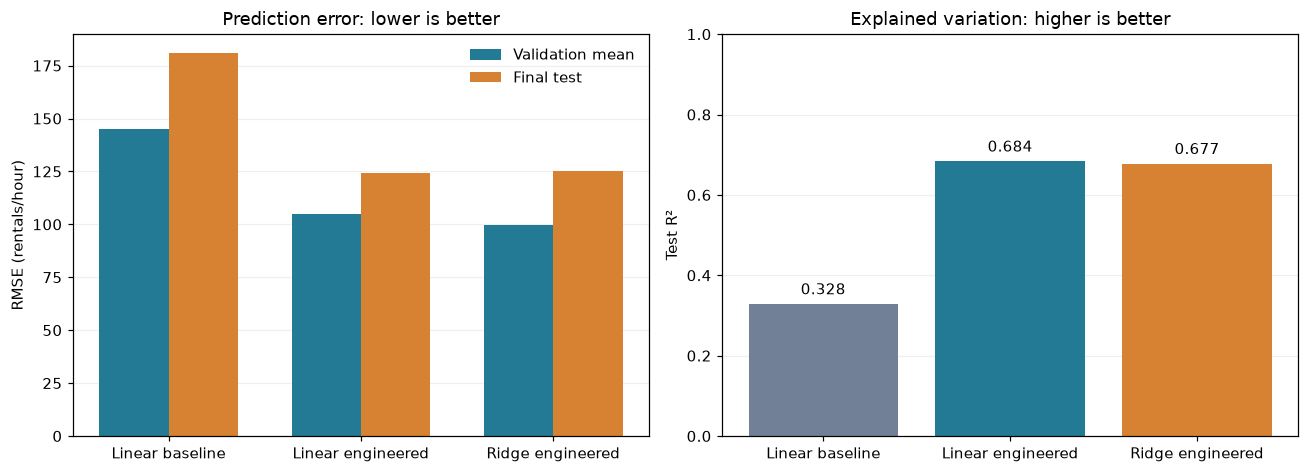

In [6]:
colors = ['#718096', '#237a94', '#d78232']
labels = ['Linear baseline', 'Linear engineered', 'Ridge engineered']
positions = np.arange(len(comparison))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].bar(positions - 0.18, comparison['CV RMSE'], width=0.36,
            color='#237a94', label='Validation mean')
axes[0].bar(positions + 0.18, comparison['Test RMSE'], width=0.36,
            color='#d78232', label='Final test')
axes[0].set(xticks=positions, xticklabels=labels, ylabel='RMSE (rentals/hour)',
            title='Prediction error: lower is better')
axes[0].legend(frameon=False)

bars = axes[1].bar(positions, comparison['Test R2'], color=colors)
axes[1].bar_label(bars, fmt='%.3f', padding=4)
axes[1].set(xticks=positions, xticklabels=labels, ylabel='Test R²',
            title='Explained variation: higher is better', ylim=(0, 1))
for axis in axes:
    axis.set_axisbelow(True)
    axis.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

**Insight:** The new feature set reduces linear regression's test RMSE from
**180.80 to 124.11 rentals/hour**, an improvement of
**31.4%**. Its test R² rises from **0.3284 to 0.6835**.
Ridge has the lowest mean validation RMSE, **99.59**, but Linear engineered
has the lowest test RMSE. Feature engineering makes a much larger difference than the choice
between the two engineered models. CV columns average the five folds; SD describes variation
in fold RMSE.

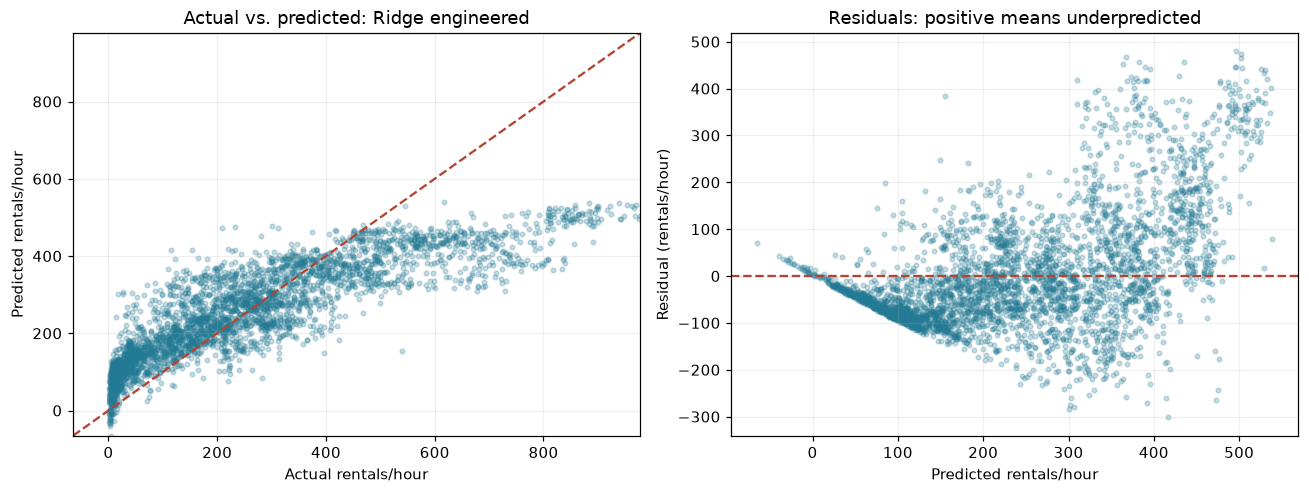

Busy-hour threshold from training: 410 rentals/hour


,Test hours,Rows,RMSE,Mean residual
0,Below training 90th percentile,2855,82.6300,-44.2000
1,At/above training 90th percentile,777,219.7800,184.8700


Negative test predictions: 25


In [7]:
residuals = y_test.to_numpy() - best_predictions
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(y_test, best_predictions, s=9, alpha=0.25, color='#237a94')
lower = min(0, best_predictions.min())
upper = max(y_test.max(), best_predictions.max())
axes[0].plot([lower, upper], [lower, upper], '--', color='#b44332', linewidth=1.5)
axes[0].set(xlabel='Actual rentals/hour', ylabel='Predicted rentals/hour',
            title=f'Actual vs. predicted: {best_name}', xlim=(lower, upper), ylim=(lower, upper))
axes[1].scatter(best_predictions, residuals, s=9, alpha=0.25, color='#237a94')
axes[1].axhline(0, linestyle='--', color='#b44332', linewidth=1.5)
axes[1].set(xlabel='Predicted rentals/hour', ylabel='Residual (rentals/hour)',
            title='Residuals: positive means underpredicted')
for axis in axes:
    axis.grid(alpha=0.2)
fig.tight_layout()
plt.show()

# Quantify the busy-hour issue seen in Deliverable 1, using a training-defined threshold.
busy_threshold = y_train.quantile(0.90)
busy = y_test.to_numpy() >= busy_threshold
error_groups = []
for label, mask in [('Below training 90th percentile', ~busy),
                    ('At/above training 90th percentile', busy)]:
    error_groups.append({'Test hours': label, 'Rows': int(mask.sum()),
                         'RMSE': np.sqrt(np.mean(residuals[mask] ** 2)),
                         'Mean residual': residuals[mask].mean()})
print(f'Busy-hour threshold from training: {busy_threshold:.0f} rentals/hour')
display(pd.DataFrame(error_groups).round(2))
print(f'Negative test predictions: {(best_predictions < 0).sum()}')

**Insight:** The scatterplot shows underprediction at high demand, and residuals do not form
a uniform band around zero. For the selected Ridge model, test hours at or above the training
90th percentile (**410 rentals/hour**) have RMSE **219.78**, compared with
**82.63** below that threshold. Their mean residual is **+184.87 rentals/hour**,
confirming underprediction in that group. The model also produces **25 negative predictions**.
Scores use the original predictions without clipping, so this limitation remains visible.

## 7. Findings, challenges, and conclusion

- **Feature engineering:** Adding the 13 features reduces validation RMSE by
  **27.7%** and test RMSE by **31.4%** for the same linear algorithm.
  This measures their combined effect, not the contribution of each feature separately.
- **Best test performance:** Linear engineered reaches **R² = 0.6835**,
  **MSE = 15,403.35**, and **RMSE = 124.11 rentals/hour**.
- **Model recommendation:** Ridge engineered, with **alpha = 100**, was selected using
  the lowest mean validation RMSE (**99.59** versus **105.00** for Linear engineered).
  Its test RMSE is **125.30**, only **1.19 rentals/hour** higher than the best test result.
  The recommendation follows training-period validation; the test comparison is reported separately.
- **Remaining error:** Both engineered models improve on the baseline, but the selected model
  still underestimates busy hours. The results do not support a claim of uniformly accurate
  peak-demand forecasts.

| Challenge | How it was addressed |
|---|---|
| Daily demand is not a straight-line relationship with hour. | Added cyclic features and working-day interactions, then measured the improvement against the same linear algorithm. |
| Weather measurements are correlated and have different spreads. | Standardized numeric inputs inside pipelines and compared Ridge with ordinary regression. |
| Later observations must not enter earlier training. | Used chronological train/test periods and five expanding calendar validation windows. |
| Rental components would reveal the answer. | Excluded casual and registered rental counts from all predictors. |
| Busy hours can have larger errors. | Kept valid high counts and reported residuals and separate busy-hour errors. |

The analysis supports planning questions about hourly bicycle and staffing demand. It uses
recorded weather during the hour, so an advance forecast would need weather forecasts available
at prediction time. These are historical records from one system. Deliverable 1 already examined
the full dataset descriptively, so the final test is a later-period check rather than a completely
unseen research dataset. The questionable zero-humidity readings noted in Deliverable 1 remain
unchanged. Only Deliverable 2 is implemented here.

## References

Fanaee-T, H. (2013). *Bike sharing* [Data set]. UCI Machine Learning Repository.
https://doi.org/10.24432/C5W894  
License: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Cleaned column names and
calendar features were prepared in Deliverables 1 and 2.

Scikit-learn developers. (n.d.). *Time-related feature engineering*.
https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html

Wu, D. (2024). *Data mining with Python: Theory, application, and case studies*. CRC Press.